In [13]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

ML_DIR = Path.cwd() if Path.cwd().name == "ml" else Path.cwd() / "ml"
DATA_PATH = ML_DIR / "data" / "farm_risk_dataset.csv"
ARTIFACTS_DIR = ML_DIR / "artifacts"
DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

FEATURE_COLUMNS = [
    "days_to_deadline",
    "farm_acres",
    "distance_to_chc_km",
    "queue_acres_ahead",
    "machine_capacity_per_day",
    "rain_delay_days",
    "available_machines_nearby",
]
TARGET_COLUMN = "deadline_miss"


def build_1lakh_dataset(n_samples: int = 100_000, seed: int = 42) -> pd.DataFrame:
    rng = np.random.default_rng(seed)

    # Baseline Patiala-Sangrur harvest distributions
    days_to_deadline = rng.integers(1, 16, size=n_samples)
    farm_acres = np.round(rng.uniform(1.5, 22.0, size=n_samples), 1)
    distance_to_chc_km = np.round(rng.uniform(0.5, 22.0, size=n_samples), 1)
    queue_acres_ahead = np.round(rng.uniform(0.0, 50.0, size=n_samples), 1)
    machine_capacity_per_day = np.round(rng.uniform(5.0, 9.5, size=n_samples), 1)
    rain_delay_days = rng.choice([0, 1, 2, 3], size=n_samples, p=[0.68, 0.18, 0.10, 0.04])
    available_machines_nearby = rng.choice([1, 2, 3, 4, 5], size=n_samples, p=[0.28, 0.30, 0.22, 0.12, 0.08])

    # Inject real-world operational anomalies (~26% of rows)
    anomaly_roll = rng.random(size=n_samples)

    # 1. Machinery breakdown / blade clogging (~10%) -> steep drop in daily capacity
    is_breakdown = anomaly_roll < 0.10
    machine_capacity_per_day = np.where(is_breakdown, np.round(rng.uniform(2.5, 4.2, size=n_samples), 1), machine_capacity_per_day)

    # 2. Western disturbance rainstorm (~8%) -> 3 to 5 delay days + wet soil drag
    is_rainstorm = (anomaly_roll >= 0.10) & (anomaly_roll < 0.18)
    rain_delay_days = np.where(is_rainstorm, rng.integers(3, 6, size=n_samples), rain_delay_days)

    # 3. Peak-week CHC congestion surge (~8%) -> tight deadline + heavy queue + single machine
    is_peak_surge = (anomaly_roll >= 0.18) & (anomaly_roll < 0.26)
    days_to_deadline = np.where(is_peak_surge, rng.integers(1, 5, size=n_samples), days_to_deadline)
    queue_acres_ahead = np.where(is_peak_surge, np.round(rng.uniform(35.0, 65.0, size=n_samples), 1), queue_acres_ahead)
    available_machines_nearby = np.where(is_peak_surge, 1, available_machines_nearby)

    # Operational clearance physics
    own_farm_days = farm_acres / machine_capacity_per_day
    parallel_queue_factor = 1.0 + 0.40 * (available_machines_nearby - 1)
    queue_clear_days = queue_acres_ahead / (machine_capacity_per_day * parallel_queue_factor)

    single_machine_penalty = np.where(available_machines_nearby == 1, 0.35, 0.10)
    travel_delay_days = (distance_to_chc_km / 25.0) + single_machine_penalty

    wet_soil_drag = np.where(is_rainstorm, 0.50, 0.0)
    operational_noise = rng.normal(loc=0.0, scale=0.35, size=n_samples)

    required_days = own_farm_days + queue_clear_days + travel_delay_days + rain_delay_days + wet_soil_drag + operational_noise
    deadline_miss = (required_days > days_to_deadline).astype(int)

    return pd.DataFrame({
        "days_to_deadline": days_to_deadline,
        "farm_acres": farm_acres,
        "distance_to_chc_km": distance_to_chc_km,
        "queue_acres_ahead": queue_acres_ahead,
        "machine_capacity_per_day": machine_capacity_per_day,
        "rain_delay_days": rain_delay_days,
        "available_machines_nearby": available_machines_nearby,
        TARGET_COLUMN: deadline_miss,
    })


df = build_1lakh_dataset(n_samples=100_000, seed=42)
df.to_csv(DATA_PATH, index=False)

counts = df[TARGET_COLUMN].value_counts()
pct = df[TARGET_COLUMN].value_counts(normalize=True) * 100
print(f"Generated & saved {len(df):,} rows -> {DATA_PATH}")
print(f"  0 (On-Time):       {counts[0]:,} ({pct[0]:.2f}%)")
print(f"  1 (Deadline Miss): {counts[1]:,} ({pct[1]:.2f}%)")
df.head()

Generated & saved 100,000 rows -> e:\SatHack\ParaliPool\ml\data\farm_risk_dataset.csv
  0 (On-Time):       57,577 (57.58%)
  1 (Deadline Miss): 42,423 (42.42%)


,days_to_deadline,farm_acres,distance_to_chc_km,queue_acres_ahead,machine_capacity_per_day,rain_delay_days,available_machines_nearby,deadline_miss
0,2,19.6,18.6,3.7,9.2,0,4,1
1,4,10.0,16.7,51.3,5.8,0,1,1
2,10,14.1,11.3,35.8,6.2,1,2,0
3,7,4.4,13.4,41.5,7.2,5,3,1
4,4,12.3,16.3,50.2,9.4,0,1,1


In [14]:
X = df[FEATURE_COLUMNS]
y = df[TARGET_COLUMN]

# 1. Carve out 15% untouched Test Set (15,000 rows)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=42
)

# 2. Split remaining 85% into 70% Train (70,000 rows) and 15% Validation (15,000 rows)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=(0.15 / 0.85), stratify=y_temp, random_state=42
)

print(f"Train rows:      {len(X_train):,}")
print(f"Validation rows: {len(X_val):,}")
print(f"Test rows:       {len(X_test):,}")

pipeline = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        (
            "mlp",
            MLPClassifier(
                hidden_layer_sizes=(32, 16, 8),
                activation="relu",
                solver="adam",
                batch_size=256,
                alpha=1e-4,
                learning_rate_init=0.001,
                max_iter=200,
                early_stopping=True,
                validation_fraction=0.1,
                n_iter_no_change=15,
                random_state=42,
            ),
        ),
    ]
)

pipeline.fit(X_train, y_train)
mlp = pipeline.named_steps["mlp"]
print(f"Training converged in {mlp.n_iter_} epochs.")

Train rows:      69,999
Validation rows: 15,001
Test rows:       15,000
Training converged in 37 epochs.


,Train (70k),Validation (15k),Held-Out Test (15k)
accuracy,0.9823,0.9837,0.9824
precision,0.9789,0.9819,0.9794
recall,0.9794,0.9797,0.9791
f1_score,0.9792,0.9808,0.9793
roc_auc,0.9990,0.9991,0.9989


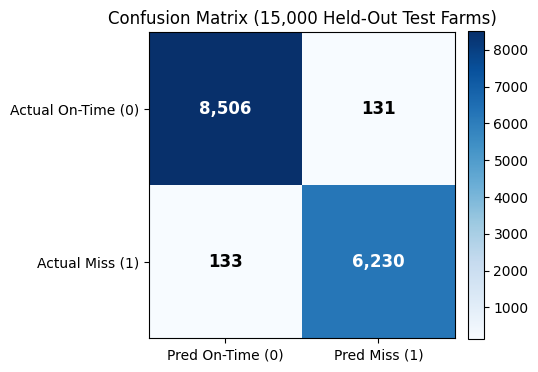

In [15]:
def evaluate_split(X_split, y_split):
    preds = pipeline.predict(X_split)
    probs = pipeline.predict_proba(X_split)[:, 1]
    return {
        "accuracy": round(float(accuracy_score(y_split, preds)), 4),
        "precision": round(float(precision_score(y_split, preds)), 4),
        "recall": round(float(recall_score(y_split, preds)), 4),
        "f1_score": round(float(f1_score(y_split, preds)), 4),
        "roc_auc": round(float(roc_auc_score(y_split, probs)), 4),
    }

comparison_df = pd.DataFrame(
    {
        "Train (70k)": evaluate_split(X_train, y_train),
        "Validation (15k)": evaluate_split(X_val, y_val),
        "Held-Out Test (15k)": evaluate_split(X_test, y_test),
    }
)
display(comparison_df)

metrics = comparison_df["Held-Out Test (15k)"].to_dict()
y_pred = pipeline.predict(X_test)
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1], labels=["Pred On-Time (0)", "Pred Miss (1)"])
ax.set_yticks([0, 1], labels=["Actual On-Time (0)", "Actual Miss (1)"])
for i in range(2):
    for j in range(2):
        color = "white" if cm[i, j] > cm.max() / 2 else "black"
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", color=color, fontsize=12, fontweight="bold")
ax.set_title("Confusion Matrix (15,000 Held-Out Test Farms)")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig(ARTIFACTS_DIR / "confusion_matrix.png", dpi=150)
plt.show()

In [18]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

models = {
    "Logistic Regression (Baseline)": Pipeline([("scaler", StandardScaler()), ("lr", LogisticRegression(max_iter=500))]),
    "Random Forest (150 Trees)": RandomForestClassifier(n_estimators=150, max_depth=14, random_state=42, n_jobs=-1),
    "3-Layer DNN (32-16-8)": pipeline,
}

benchmark_rows = []
for name, clf in models.items():
    if name != "3-Layer DNN (32-16-8)":
        clf.fit(X_train, y_train)
    preds = clf.predict(X_test)
    probs = clf.predict_proba(X_test)[:, 1]
    benchmark_rows.append({
        "Model": name,
        "Accuracy": round(float(accuracy_score(y_test, preds)), 4),
        "Precision": round(float(precision_score(y_test, preds)), 4),
        "Recall (Priority)": round(float(recall_score(y_test, preds)), 4),
        "F1-Score": round(float(f1_score(y_test, preds)), 4),
        "ROC-AUC": round(float(roc_auc_score(y_test, probs)), 4),
    })

benchmark_df = pd.DataFrame(benchmark_rows)
display(benchmark_df)

,Model,Accuracy,Precision,Recall (Priority),F1-Score,ROC-AUC
0,Logistic Regression (Baseline),0.9537,0.9456,0.9452,0.9454,0.9923
1,Random Forest (150 Trees),0.9704,0.9727,0.9571,0.9648,0.9972
2,3-Layer DNN (32-16-8),0.9824,0.9794,0.9791,0.9793,0.9989


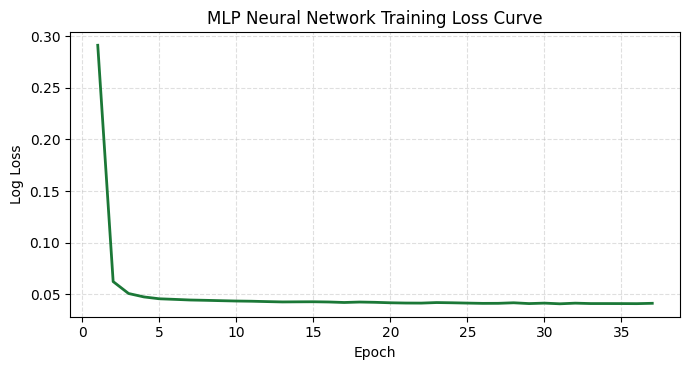

,feature,importance_mean,importance_std
0,days_to_deadline,0.3793,0.0036
1,queue_acres_ahead,0.1056,0.0020
2,machine_capacity_per_day,0.0782,0.0014
3,rain_delay_days,0.0653,0.0012
4,available_machines_nearby,0.0533,0.0012
5,farm_acres,0.0510,0.0014
6,distance_to_chc_km,0.0066,0.0006


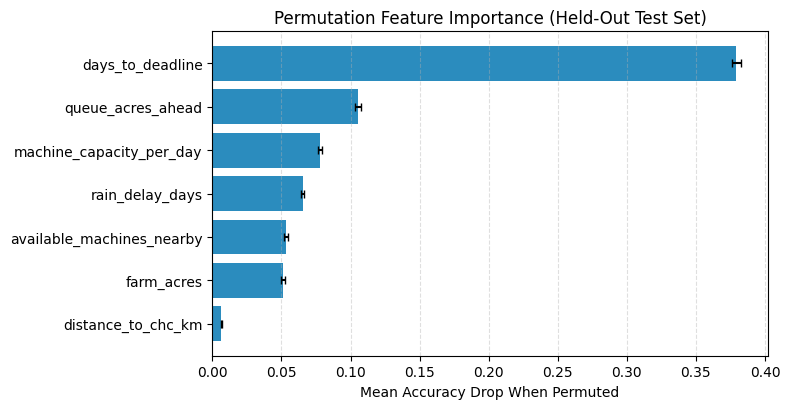

In [16]:
# Training Loss Curve
loss_curve = [round(float(v), 5) for v in mlp.loss_curve_]
plt.figure(figsize=(7, 3.8))
plt.plot(range(1, len(loss_curve) + 1), loss_curve, color="#1b7837", linewidth=2)
plt.title("MLP Neural Network Training Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Log Loss")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig(ARTIFACTS_DIR / "training_loss_curve.png", dpi=150)
plt.show()

# Permutation Feature Importance
perm = permutation_importance(pipeline, X_test, y_test, n_repeats=15, random_state=42, scoring="accuracy")
importance_df = (
    pd.DataFrame({
        "feature": FEATURE_COLUMNS,
        "importance_mean": perm.importances_mean,
        "importance_std": perm.importances_std,
    })
    .sort_values("importance_mean", ascending=False)
    .reset_index(drop=True)
)
display(importance_df.round(4))

ordered = importance_df.sort_values("importance_mean", ascending=True)
plt.figure(figsize=(8, 4.2))
plt.barh(ordered["feature"], ordered["importance_mean"], xerr=ordered["importance_std"], color="#2b8cbe", capsize=3)
plt.title("Permutation Feature Importance (Held-Out Test Set)")
plt.xlabel("Mean Accuracy Drop When Permuted")
plt.grid(True, axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig(ARTIFACTS_DIR / "feature_importance.png", dpi=150)
plt.show()

In [17]:
model_path = ARTIFACTS_DIR / "risk_model.joblib"
joblib.dump(
    {
        "pipeline": pipeline,
        "feature_columns": FEATURE_COLUMNS,
        "thresholds": {"medium": 35.0, "high": 70.0},
        "risk_type": "DEADLINE_MISS",
    },
    model_path,
)

metrics_payload = {
    "model_name": "ParaliPool Farm Risk Intelligence Engine",
    "architecture": {
        "scaler": "StandardScaler",
        "classifier": "MLPClassifier",
        "hidden_layers": [32, 16, 8],
        "activation": "relu",
        "optimizer": "adam",
        "epochs_trained": int(mlp.n_iter_),
    },
    "dataset": {
        "total_rows": int(len(df)),
        "train_rows": int(len(X_train)),
        "test_rows": int(len(X_test)),
        "positive_class_rate": round(float(y.mean()), 4),
    },
    "test_metrics": metrics,
    "confusion_matrix": {
        "labels": ["0_ON_TIME", "1_DEADLINE_MISS"],
        "matrix": cm.tolist(),
        "tn": int(cm[0, 0]),
        "fp": int(cm[0, 1]),
        "fn": int(cm[1, 0]),
        "tp": int(cm[1, 1]),
    },
    "permutation_importance": [
        {
            "feature": row["feature"],
            "importance_mean": round(float(row["importance_mean"]), 4),
            "importance_std": round(float(row["importance_std"]), 4),
        }
        for _, row in importance_df.iterrows()
    ],
    "loss_curve": loss_curve,
}

metrics_path = ARTIFACTS_DIR / "model_metrics.json"
with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics_payload, f, indent=2)

print(f"Exported model   -> {model_path}")
print(f"Exported metrics -> {metrics_path}")

Exported model   -> e:\SatHack\ParaliPool\ml\artifacts\risk_model.joblib
Exported metrics -> e:\SatHack\ParaliPool\ml\artifacts\model_metrics.json
